In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier

The objective of this lab is comparing classification models that predict the popularity
class of a song using its musical characteristics.
The target variable will have three classes: Low, Medium and High.

In [2]:
# 1.- EXPLORING THE DATASET
# ---------------------------------------------------------------

print("1.- EXPLORING THE DATASET")
print("-"*30)

df = pd.read_csv("comercial.csv")
print(f"\n\nDataset shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")

print("\n\nFirst 20 rows:")
display(df.head(20))

df.info()
display(df.describe(include="all").T)

# Cleaning/filetering data

missing_values = df.isna().sum()

print("\n\n\nMissing values by column: \n")
display(missing_values[missing_values >0])

print(f"\nExact duplicated rows: {df.duplicated().sum()}")

repeated_tracks = df.duplicated(
    subset = ["artist", "song"]
).sum()

print(f"\n\nRepeated artist-song rows: {repeated_tracks}\n")

# 2.- DATA PREPARATION
# ---------------------------------------------------------------

print ("\n\n\n\n2.- DATA PREPARATION")
print ("-"*30)

# Removing rows which Popularity value is not valid
data = df.dropna(subset=["popularity"]).copy()

print(f"\n\n\nRows left after removing incomplete fields: {len(data)}\n")


# Selection of features
features = [
    "total_track_album",
    "danceability",
    "energy",
    "loudness",
    "mode",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

print (f"\nSelected features: \n")
for feat in features:
    print(feat)

# Checking popularity/selected musical feat change between observations of the same track

columns_to_check = ["popularity"] + features

inconsistent_tracks = (
    data.groupby(["artist", "song"])[columns_to_check]
    .nunique()
    .gt(1)
    .any(axis=1)
    .sum()
)

print(f"\n\nArtist-song groups with inconsistent target/features: {inconsistent_tracks}")

# Keeping one row per artist-song
data = data.drop_duplicates(
    subset=["artist", "song"]
).copy()

print (f"\n\nRows after keeping unique tracks: {len(data)}")

# Checking missing values in selected feats
print (f"\n\nMissing values in selected features: {data[features].isna().sum().sum()}\n\n")

1.- EXPLORING THE DATASET
------------------------------


Dataset shape: (478103, 19)

Columns: ['artist', 'song', 'hour', 'date', 'popularity', 'album_name', 'release_date', 'total_track_album', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']


First 20 rows:


,artist,song,hour,date,popularity,album_name,release_date,total_track_album,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,Years & Years,It's a Sin,00:58,01/01/2020,43.0,It’s a sin,2021-05-11,1.0,0.596,0.891,0.0,-5.925,0.0,0.0429,0.0350,0.000004,0.1860,0.200,124.986
1,David Fonseca,Someone that Cannot Love,00:54,01/01/2020,31.0,Sing Me Something New,2003-01-01,15.0,0.460,0.528,0.0,-7.249,1.0,0.0268,0.2800,0.000070,0.1310,0.430,151.207
2,Pearl Jam,Just Breathe,00:50,01/01/2020,66.0,Backspacer,2009-09-19,12.0,0.473,0.348,0.0,-11.100,1.0,0.0288,0.7210,0.000074,0.0823,0.283,107.819
3,"Ed Sheeran, Taylor Swift",The Joker and the Queen,00:47,01/01/2020,63.0,The Joker And The Queen (feat. Taylor Swift),2022-02-11,1.0,0.528,0.309,0.0,-7.398,1.0,0.0329,0.9240,0.000002,0.2820,0.307,133.830
4,Seal,Stand by Me,00:43,01/01/2020,38.0,Soul,2008-10-31,12.0,0.734,0.409,9.0,-7.596,1.0,0.0280,0.2460,0.000000,0.1280,0.779,107.453
5,HMB,Já Não Sou Bom A Mentir,00:40,01/01/2020,21.0,Neste Deserto Nascem Flores,2024-03-15,10.0,0.364,0.503,0.0,-5.923,1.0,0.0326,0.1540,0.000000,0.1250,0.373,119.743
6,Olivia Dean,Dive,00:36,01/01/2020,72.0,Messy,2023-06-30,12.0,0.630,0.754,7.0,-5.982,1.0,0.0433,0.1480,0.000141,0.1310,0.279,90.051
7,"Max, Gnash",Lights Down Low,00:33,01/01/2020,45.0,Lights Down Low - EP,2016-10-14,3.0,0.622,0.571,0.0,-5.338,0.0,0.0493,0.0458,0.000000,0.1220,0.635,81.059
8,Richie Campbell,Get with You,00:28,01/01/2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Norah Jones,Sunrise,00:25,01/01/2020,74.0,Feels Like Home,2004-01-01,13.0,0.526,0.299,8.0,-13.797,1.0,0.0310,0.9410,0.097000,0.1060,0.679,156.848


<class 'pandas.DataFrame'>
RangeIndex: 478103 entries, 0 to 478102
Data columns (total 19 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   artist             478103 non-null  str    
 1   song               478103 non-null  str    
 2   hour               478103 non-null  str    
 3   date               478103 non-null  str    
 4   popularity         474423 non-null  float64
 5   album_name         474423 non-null  str    
 6   release_date       474423 non-null  str    
 7   total_track_album  474423 non-null  float64
 8   danceability       474423 non-null  float64
 9   energy             474423 non-null  float64
 10  key                474423 non-null  float64
 11  loudness           474423 non-null  float64
 12  mode               474423 non-null  float64
 13  speechiness        474423 non-null  float64
 14  acousticness       474423 non-null  float64
 15  instrumentalness   474423 non-null  float64
 16  liveness     

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
artist,478103,422,Coldplay,11160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
song,478103,616,Houdini,7367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hour,478103,1023,00:43,1828,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,478103,1829,25/09/2024,317,NaN,NaN,NaN,NaN,NaN,NaN,NaN
popularity,474423.0,NaN,NaN,NaN,62.777846,21.399429,0.0,46.0,66.0,81.0,100.0
album_name,474423,510,Trovador,9094,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_date,474423,403,2024-06-21,19360,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_track_album,474423.0,NaN,NaN,NaN,9.583003,9.999143,1.0,1.0,10.0,14.0,79.0
danceability,474423.0,NaN,NaN,NaN,0.613197,0.130961,0.162,0.527,0.608,0.712,0.936
energy,474423.0,NaN,NaN,NaN,0.628949,0.173671,0.084,0.49,0.652,0.769,0.989





Missing values by column: 



popularity           3680
album_name           3680
release_date         3680
total_track_album    3680
danceability         3680
energy               3680
key                  3680
loudness             3680
mode                 3680
speechiness          3680
acousticness         3680
instrumentalness     3680
liveness             3680
valence              3680
tempo                3680
dtype: int64


Exact duplicated rows: 0


Repeated artist-song rows: 477478





2.- DATA PREPARATION
------------------------------



Rows left after removing incomplete fields: 474423


Selected features: 

total_track_album
danceability
energy
loudness
mode
speechiness
acousticness
instrumentalness
liveness
valence
tempo


Artist-song groups with inconsistent target/features: 0


Rows after keeping unique tracks: 600


Missing values in selected features: 0




now that all the information is filtered, it is clear that there are no
incomplete rows left in the dataset.

The original Popularity variable is numerical, so it must be converted
into a categorical variable.
The three classes, as previously noted, are:
- Low: 0-49
- Medium: 50-74
- High: 75-100

In [3]:
popularity_bins = [0, 50, 75, 101]
class_names = ["Low", "Medium", "High"]

# Conversion
data ["popularity_class"] = pd.cut(
    data ["popularity"],
    bins = popularity_bins,
    labels = class_names,
    right = False,  # this line will includde tracks with score=limit in the highest category
    include_lowest = True
)

# Number of tracks per class
class_counts = (
    data["popularity_class"]
    .value_counts()
    .reindex(class_names)
)
print ("\n\nNumber of tracks per class: ")
display (class_counts.to_frame("Number of tracks"))

# Show proportion % of total tracks per class
class_percentages = (
    data["popularity_class"]
    .value_counts(normalize = True)
    .reindex (class_names) * 100
)
display(class_percentages.round(2).to_frame("Track proportion (%)"))



Number of tracks per class: 


,Number of tracks
popularity_class,
Low,144
Medium,261
High,195


,Track proportion (%)
popularity_class,
Low,24.0
Medium,43.5
High,32.5


The Medium class is the biggest, containing 43.5% of the tracks in the dataset.

In [4]:
# Checking that most of musical features have homogeneous ranks (0-1)
display (data[["popularity"] + features].describe().T)

bounded_features = [
    "danceability",
    "energy",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence"
]


# Searching values out of the range set
print ("\n\nValues outside the expected [0,1] interval: ")

for column in bounded_features:
    outside = ((data[column] <0) | (data[column] >1)).sum()
    print(column, ":", outside)

,count,mean,std,min,25%,50%,75%,max
popularity,600.0,63.623333,18.711717,0.000000,50.75000,6.900000e+01,78.000000,100.000
total_track_album,600.0,11.863333,8.068653,1.000000,9.00000,1.200000e+01,15.000000,79.000
danceability,600.0,0.593720,0.138660,0.162000,0.50000,6.020000e-01,0.692250,0.936
energy,600.0,0.604397,0.193434,0.084000,0.45725,6.160000e-01,0.760000,0.989
loudness,600.0,-6.760580,2.439831,-18.798000,-8.05600,-6.316000e+00,-5.111500,-1.248
mode,600.0,0.680000,0.466865,0.000000,0.00000,1.000000e+00,1.000000,1.000
speechiness,600.0,0.066825,0.071231,0.023100,0.03220,4.145000e-02,0.063775,0.518
acousticness,600.0,0.315383,0.297282,0.000048,0.04320,2.230000e-01,0.553250,0.979
instrumentalness,600.0,0.008411,0.056106,0.000000,0.00000,5.100000e-07,0.000054,0.689
liveness,600.0,0.164557,0.136076,0.023200,0.09670,1.160000e-01,0.169500,0.969




Values outside the expected [0,1] interval: 
danceability : 0
energy : 0
speechiness : 0
acousticness : 0
instrumentalness : 0
liveness : 0
valence : 0


the musical features of all the rows are inside range. Some other features, like tempo
or key, follow their own score systems, so they have not been included in this filter.

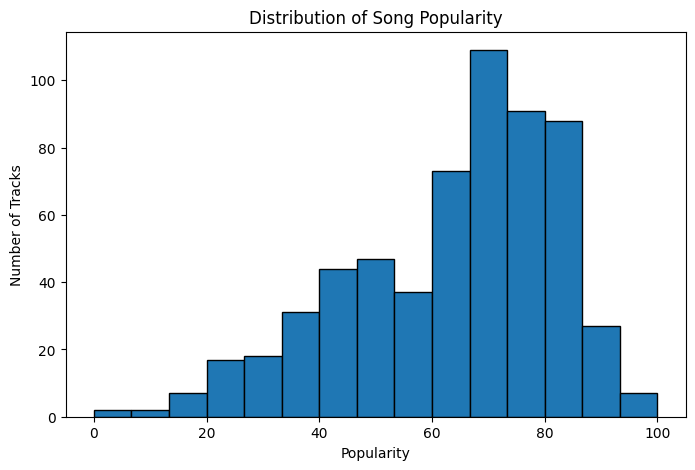

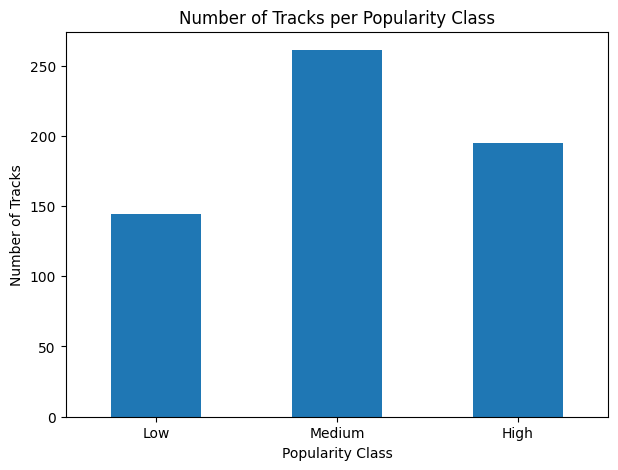

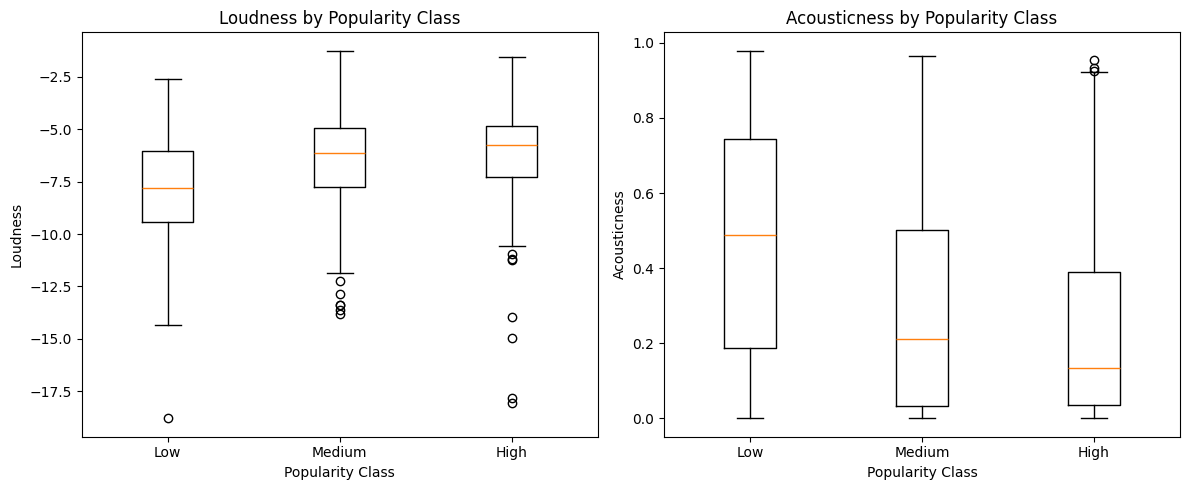

In [5]:
# Representation
# -------------------------


# Distribution of Song Popularity
plt.figure(figsize=(8, 5))

plt.hist(
    data["popularity"],
    bins=15,
    edgecolor="black"
)

plt.title("Distribution of Song Popularity")
plt.xlabel("Popularity")
plt.ylabel("Number of Tracks")

plt.show()



# Number of Tracks per Popularity Class
plt.figure(figsize=(7, 5))

class_counts.plot(kind="bar")

plt.title("Number of Tracks per Popularity Class")
plt.xlabel("Popularity Class")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=0)

plt.show()


# Relation between popularity and two of the musical features
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, column, label in zip(
    axes,
    ["loudness", "acousticness"],
    ["Loudness", "Acousticness"]
):
    grouped_values = [
        data.loc[
            data["popularity_class"] == class_name,
            column
        ].dropna()
        for class_name in class_names
    ]

    ax.boxplot(grouped_values)
    ax.set_title(f"{label} by Popularity Class")
    ax.set_xlabel("Popularity Class")
    ax.set_ylabel(label)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(class_names)

plt.tight_layout()
plt.show()

After cleaning the data taking out repeated observations for the same song and
rows without popularity score, 600 unique tracks remain.
The medium class contains the larger amount of tracks. At the same time, all three classes
are reasonably represented.

The numerical analysis suggests that "loudness" and "energy" tend to have positive relationships
with popularity while "acousticness" has a negative relationship, however these relationships are
not strong enough to guarantee 100% accurate predictions.

Artists/Songs/Albums titles and names will not be used as input features since they could mistrack
the models into memorizing identities instead of focusing on relationships among features.

In [6]:
# 3.- CREATE TRAINING AND TEST DATA
# ---------------------------------------------------------------


# input features from before
x = data[features].copy()

# classification target
y = data["popularity_class"].copy()

# split data
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.20,   #as in lab 1, 20% for the test, 80% for training
    random_state = 42,
    stratify = y
)


print("\n\n\n3.- CREATE TRAINING AND TEST DATA")
print ("-"*30)
print (f"\n\nTraining set shape: {x_train.shape}")
print (f"\n\nTest set shape: {x_test.shape}\n\n\n")




3.- CREATE TRAINING AND TEST DATA
------------------------------


Training set shape: (480, 11)


Test set shape: (120, 11)





The two classification algorithms used will be:
- K-Nearest Neighbors/KNN: classifies a track by looking at adjacent tracks
in the training data. Feature scaling is necessary because the numerical
variables have different scales.
- Decision Tree: can represent nonlinear relationships and doesn't require
feature scaling.

The same training data will be used for both models.7

In [ ]:
print ("4.- BUILDING THE CLASIFICATION MODELS")
print ("-"*30)
print("\n\n")


models = {
    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier())
    ]),

    "Decision Tree": Pipeline([
        ("model", DecisionTreeClassifier(random_state = 42))
    ])
}

# stratified five fold validation
cv = StratifiedKFold(
    n_splits = 5,
    shuffle = True,
    random_state = 42
)


# initial cross validation score for each model
baseline_cv_scores = {}

for model_name, model in models.items():

    scores = cross_val_score(   #trains model with different sets
        model,
        x_train,
        y_train,
        cv = cv,
        scoring = "accuracy"
    )

    baseline_cv_scores[model_name] = scores.mean()

    print (f"\nModel: {model_name}\n")
    print (f"Scores for the five folds: {scores.round(3)}\n")
    print (f"Mean accuracy: {round(scores.mean(), 3)}\n\n")


# hyperparameters

param_grids = {
     "K-Nearest Neighbors": {
        "model__n_neighbors": [3, 5, 7, 9, 11]  # number of neighbor tracks used for classification
    },

    "Decision Tree": {
        "model__max_depth": [3, 5, 10, None],   # limits depth
        "model__min_samples_leaf": [1, 5, 10]   # set leaves
    }
}

# best models and cross validation scores
best_models = {}
tuned_cv_scores = {}
best_parameters = {}




# 5.- TUNING THE MODELS (before comparison)
# ---------------------------------------------------------------


print ("5.- TUNING THE MODELS (before comparison)")
print ("-"*30)
print("\n\n")



# tuning the models using the training data
for model_name, model in models.items():

    grid_search = GridSearchCV(
        estimator = model,
        param_grid = param_grids[model_name],
        cv = cv,
        scoring = "accuracy",
        refit = True    #once best config is chosen(cv) the model trains again with all the traning set
    )

    grid_search.fit(x_train, y_train)

    # best version of each model
    best_models[model_name] = grid_search.best_estimator_

    # best cross validation score
    tuned_cv_scores[model_name] = grid_search.best_score_

    # best hyperparameters
    best_parameters[model_name] = grid_search.best_params_

    print("\nModel:", model_name)
    print("Best parameters:", grid_search.best_params_)
    print("Best cross-validation accuracy:",
          round(grid_search.best_score_, 3))

4.- BUILDING THE CLASIFICATION MODELS
------------------------------




Model: K-Nearest Neighbors

Scores for the five folds: [0.365 0.427 0.385 0.375 0.344]

Mean accuracy: 0.379



Model: Decision Tree

Scores for the five folds: [0.333 0.281 0.365 0.323 0.417]

Mean accuracy: 0.344



Model: K-Nearest Neighbors
Best parameters: {'model__n_neighbors': 7}
Best cross-validation accuracy: 0.381

Model: Decision Tree
Best parameters: {'model__max_depth': 3, 'model__min_samples_leaf': 1}
Best cross-validation accuracy: 0.41


,Model,Baseline CV Accuracy,Tuned CV Accuracy,Improvement
0,K-Nearest Neighbors,0.379,0.381,0.002
1,Decision Tree,0.344,0.410,0.067


,Accuracy,Precision,Recall,F1-score
Model,,,,
K-Nearest Neighbors,0.392,0.394,0.392,0.393
Decision Tree,0.325,0.328,0.325,0.325





Confusion Matrix - K-Nearest Neighbors


,Low,Medium,High
Low,11,7,11
Medium,10,25,17
High,10,18,11


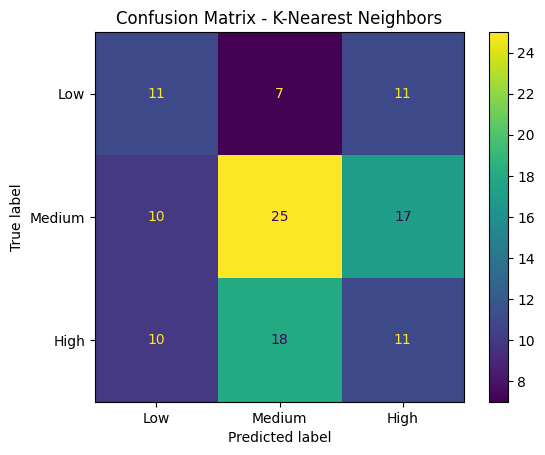

Confusion Matrix - Decision Tree


,Low,Medium,High
Low,11,9,9
Medium,17,17,18
High,8,20,11


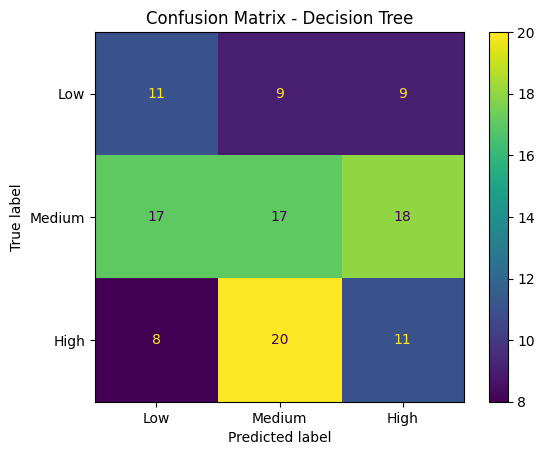

Baseline predicted class: Medium
Baseline test accuracy: 0.433


In [8]:
# 6.- COMPARISON AND EVALUATION
# ---------------------------------------------------------------

comparison = pd.DataFrame ({
    "Model": list (models.keys()),
    "Baseline CV Accuracy": [
        baseline_cv_scores[name]
        for name in models
    ],
    "Tuned CV Accuracy": [
        tuned_cv_scores[name]
        for name in models
    ]
})

comparison["Improvement"] = (
    comparison["Tuned CV Accuracy"] - comparison["Baseline CV Accuracy"])

display (comparison.round(3))

print ("\n\n")


# final results
final_metrics = []

for model_name, model in best_models.items():


    y_pred = model.predict(x_test)

    accuracy = accuracy_score(y_test, y_pred)


    precision = precision_score(
        y_test,
        y_pred,
        average = "weighted",
        zero_division = 0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average = "weighted",
        zero_division = 0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average = "weighted",
        zero_division = 0
    )

    final_metrics.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

#display
final_results = pd.DataFrame(final_metrics).set_index("Model")

display(final_results.round(3))

print("\n\n")

# condufsion matrix
for model_name, model in best_models.items():

    y_pred = model.predict(x_test)

    cm = confusion_matrix(y_test, y_pred, labels = class_names
    )

    print(f"Confusion Matrix - {model_name}")

    display (pd.DataFrame(cm,
                          index = class_names,
                          columns = class_names))

    # visual
    display_matrix = ConfusionMatrixDisplay(confusion_matrix = cm,
                                            display_labels = class_names)

    display_matrix.plot(values_format = "d")

    plt.title(f"Confusion Matrix - {model_name}")
    plt.show()

    # Compare the models with a simple baseline

baseline_model = DummyClassifier(strategy="most_frequent")

# Train the baseline using the training data
baseline_model.fit(x_train, y_train)

# Predict the test data
baseline_predictions = baseline_model.predict(x_test)

# Calculate baseline accuracy
baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print("Baseline predicted class:", baseline_predictions[0])
print("Baseline test accuracy:", round(baseline_accuracy, 3))

# 7.- CONCLUSSION

In this lab, K-Nearest Neighbors (KNN) and Decision Tree (DT) were used to classify music tracks
into three popularity classes: Low, Medium, High.
Both models were evaluated using 5-fold cross-validation and tuned using different hyperparameters.

Before tuning, KNN achieved a CV accuracy of 37,9%, which increased slightly to 38,1% after tuning.
DT improved from 34,3% to 41%. Therefore, DT achieved the highest CV acc. after tuning

However the final results were different: KNN achieved an acc. of 39,2% while DT achieved 32,5%.
KNN also achieved highest weighetd Precision, Recall and F1 score than DT:

| Model | Precision | Recall | F1-score |
|---|---:|---:|---:|
| KNN | 39,4% | 39,2% | 39,3% |
| DT | 32,8% | 32,5% | 32,5% |


The confusion matrices show that KNN classified the Medium class most correctly, succesfully identifying
25 out of 52 tracks. For the Low class, both models correctly classified 11 out of 29. For the High class,
both correctly classified as well 11 out of 39.
On the other hand, both models present difficulties when identifying high popular songs, where KNN incorrectly
classified 18 High tracks as Medium and the DT made the same mistake with 20 tracks.

Neither model provides a strong result nor improvement for this dataset, but KNN suits it better due to the
better results, eventhough the performance is still limited.
Overall, the results suggest that the provided musical features in the dataset would not be enough
data to feed a reliable popularity prediction.

# Comparison with a Simple Baseline

A simple baseline model was also evaluated by always predicting the most frequent class: Medium. This model achieved a test accuracy of approximately 43,3%, which is higher than both KNN(39,9%) and DT(32,5%).

Therefore although KNN performed better than DT, neither classifier improved on this simple baseline in terms of general accuracy. This indicates that both of the models have important limitations when prediciting song popularity.



Tha dataset contains only 600 unique music tracks after removing repeated observations and cleaning rows with unvalid values. A bigger data set with more tracks and more features could improve overall results.
